## <span style="color: #EE82EE;">**Разработка системы анализа пользовательских предпочтений в кино методами машинного обучения**</span>

In [44]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
from scipy import stats
import time, os, json, joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, ndcg_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

MOVIELENS_PATH = Path("data/raw/ml-latest-small")

ratings = pd.read_csv(MOVIELENS_PATH / "ratings.csv")
movies = pd.read_csv(MOVIELENS_PATH / "movies.csv")
tags = pd.read_csv(MOVIELENS_PATH / "tags.csv")

#### <span style="color: #EE82EE;">**Разделение набора на исходную часть и порции**</span>

In [4]:
RAW_DIR = Path("data/raw")
INCOMING_DIR = Path("data/incoming")

ratings = ratings.sort_values("timestamp").reset_index(drop=True)

n = len(ratings)
train_end = int(n * 0.60)
batch_size = int(n * 0.40 / 4)

train_initial = ratings.iloc[:train_end].copy()
train_initial.to_csv(RAW_DIR / "train_initial.csv", index=False)
movies.to_csv(RAW_DIR / "movies.csv", index=False)

batches = {}
for i in range(4):
    start = train_end + i * batch_size
    end = train_end + (i + 1) * batch_size if i < 3 else n
    name = f"batch_0{i+1}"
    batches[name] = ratings.iloc[start:end].copy()
    batches[name].to_csv(INCOMING_DIR / f"{name}.csv", index=False)

#### <span style="color: #EE82EE;">**Анализ целевой переменной**</span>

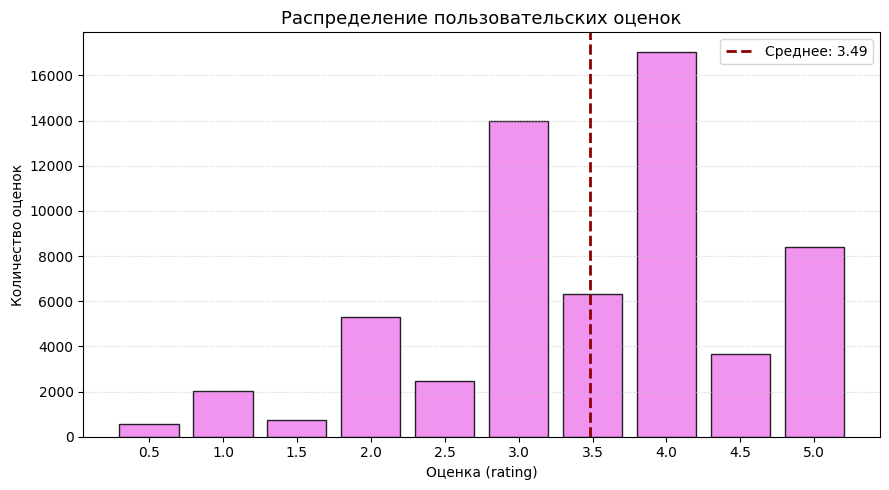

In [5]:
mean_rating = train_initial['rating'].mean()
counts = train_initial['rating'].value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(counts.index.astype(str), counts.values, color='#EE82EE', edgecolor='black', alpha=0.85)

x_pos = (mean_rating - 0.5) / 0.5
plt.axvline(x_pos, color='darkred', linestyle='--', linewidth=2, label=f'Среднее: {mean_rating:.2f}')

plt.title('Распределение пользовательских оценок', fontsize=13)
plt.xlabel('Оценка (rating)')
plt.ylabel('Количество оценок')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
balance = (train_initial['rating'] >= 4.0).value_counts(normalize=True) * 100
print(f"Релевантные (>=4.0): {balance[True]:.1f}%\nНерелевантные (<4.0): {balance[False]:.1f}%")

Релевантные (>=4.0): 48.1%
Нерелевантные (<4.0): 51.9%


#### <span style="color: #EE82EE;">**Оценка качества данных**</span>

In [8]:
print("1. Пропуски:\n", train_initial.isna().sum())
print("2. Точные дубли:", train_initial.duplicated().sum())
print("   Дубли пар userId-movieId:", train_initial.duplicated(subset=['userId', 'movieId']).sum())
print("3. Ошибки ID (<= 0):", ((train_initial['userId'] <= 0) | (train_initial['movieId'] <= 0)).sum())
print("   Ошибки рейтинга:", (~train_initial['rating'].isin([x * 0.5 for x in range(1, 11)])).sum())
print("   Диапазон дат:", pd.to_datetime(train_initial['timestamp'], unit='s').agg(['min', 'max']).to_dict())

1. Пропуски:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
2. Точные дубли: 0
   Дубли пар userId-movieId: 0
3. Ошибки ID (<= 0): 0
   Ошибки рейтинга: 0
   Диапазон дат: {'min': Timestamp('1996-03-29 18:36:55'), 'max': Timestamp('2009-11-17 01:21:40')}


#### <span style="color: #EE82EE;">**Распределение пользовательской активности**</span>

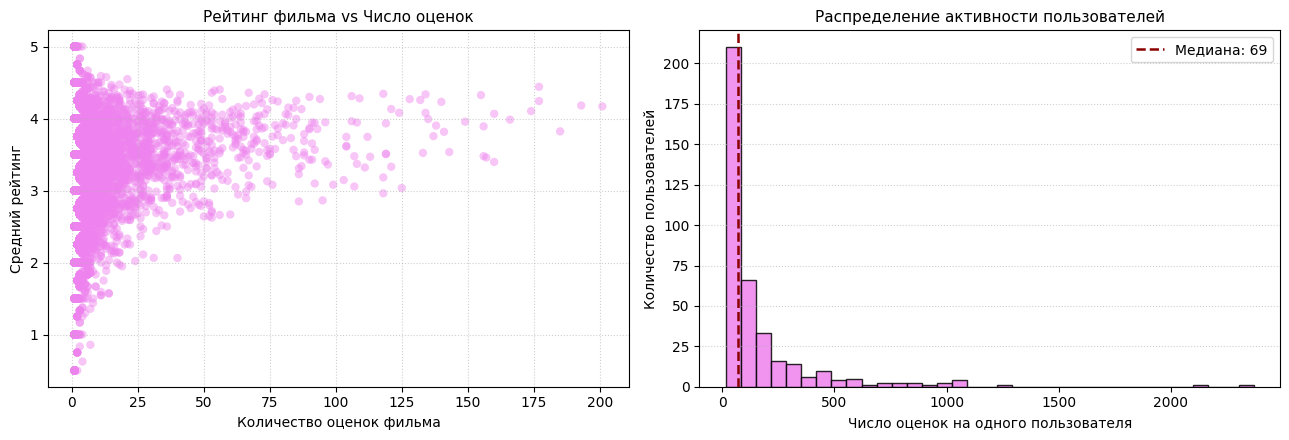

In [9]:
m_stats = train_initial.groupby('movieId')['rating'].agg(['count', 'mean'])
u_counts = train_initial.groupby('userId')['rating'].count()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.scatter(m_stats['count'], m_stats['mean'], color='#EE82EE', alpha=0.45, edgecolors='none')
ax1.set_title('Рейтинг фильма vs Число оценок', fontsize=11)
ax1.set_xlabel('Количество оценок фильма')
ax1.set_ylabel('Средний рейтинг')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.hist(u_counts, bins=35, color='#EE82EE', edgecolor='black', alpha=0.85)
ax2.axvline(u_counts.median(), color='darkred', linestyle='--', linewidth=1.8, 
            label=f'Медиана: {u_counts.median():.0f}')
ax2.set_title('Распределение активности пользователей', fontsize=11)
ax2.set_xlabel('Число оценок на одного пользователя')
ax2.set_ylabel('Количество пользователей')
ax2.grid(axis='y', linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

#### <span style="color: #EE82EE;">**Исследование взаимосвязей между признаками**</span>

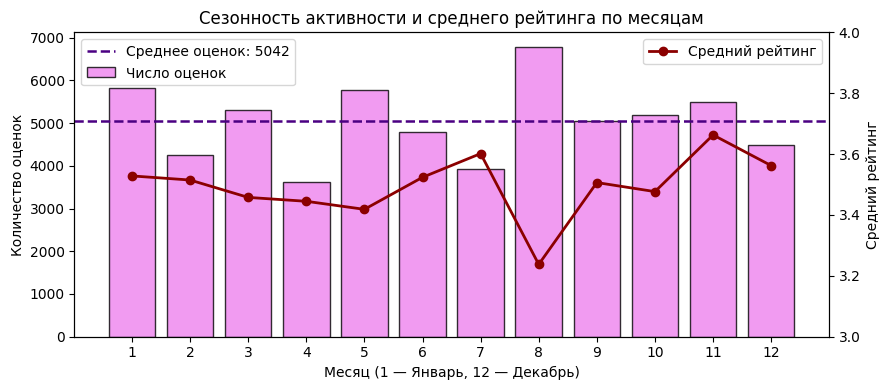

In [18]:
df_time = train_initial.copy()
df_time['month'] = pd.to_datetime(df_time['timestamp'], unit='s').dt.month
monthly = df_time.groupby('month')['rating'].agg(['count', 'mean'])

fig, ax1 = plt.subplots(figsize=(9, 4))

mean_cnt = monthly['count'].mean()
ax1.bar(monthly.index, monthly['count'], color='#EE82EE', alpha=0.8, edgecolor='black', label='Число оценок')
ax1.axhline(mean_cnt, color='indigo', linestyle='--', linewidth=1.8, label=f'Среднее оценок: {mean_cnt:.0f}')
ax1.set_xlabel('Месяц (1 — Январь, 12 — Декабрь)')
ax1.set_ylabel('Количество оценок')
ax1.set_xticks(range(1, 13))
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['mean'], color='darkred', marker='o', linewidth=2, label='Средний рейтинг')
ax2.set_ylabel('Средний рейтинг')
ax2.set_ylim(3.0, 4.0)
ax2.legend(loc='upper right')

plt.title('Сезонность активности и среднего рейтинга по месяцам', fontsize=12)
plt.tight_layout()
plt.show()

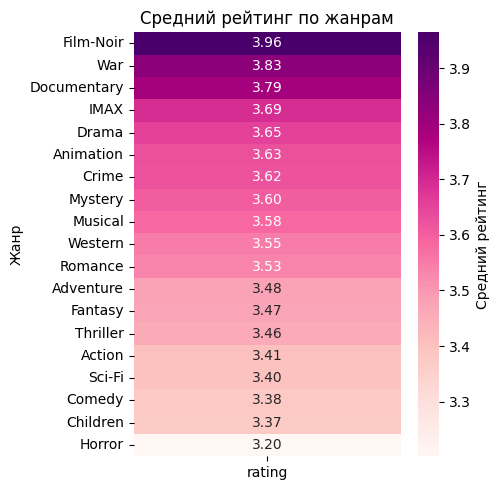

In [15]:
merged = train_initial.merge(movies[['movieId', 'genres']], on='movieId')
exploded = merged.assign(genre=merged['genres'].str.split('|')).explode('genre')
genre_mean = exploded[exploded['genre'] != '(no genres listed)'].groupby('genre')[['rating']].mean().sort_values('rating', ascending=False)

plt.figure(figsize=(5, 5))
sns.heatmap(genre_mean, annot=True, fmt='.2f', cmap='RdPu', cbar_kws={'label': 'Средний рейтинг'})

plt.title('Средний рейтинг по жанрам', fontsize=12)
plt.ylabel('Жанр')
plt.xlabel('')
plt.tight_layout()
plt.show()

#### <span style="color: #EE82EE;">**Проверка гипотез**</span>

In [22]:
m = train_initial.groupby('movieId')['rating'].agg(['count', 'mean', 'std'])
med = m['count'].median()
_, p1 = stats.ttest_ind(m[m['count'] > med]['mean'], m[m['count'] <= med]['mean'], equal_var=False)

_, p2 = stats.chisquare(train_initial['rating'].value_counts())

m_sub = m[m['count'] >= 10].join(movies.set_index('movieId')['genres'])
m_sub['n_genres'] = m_sub['genres'].str.count(r'\|') + 1
corr, p3 = stats.spearmanr(m_sub['n_genres'], m_sub['std'])

print(f"H1 (t-test) p-value: {p1:.2e}\nH2 (chi2)   p-value: {p2:.2e}\nH3 (corr):  r={corr:.3f}, p-value={p3:.2e}")

H1 (t-test) p-value: 3.79e-13
H2 (chi2)   p-value: 0.00e+00
H3 (corr):  r=-0.027, p-value=2.82e-01


#### <span style="color: #EE82EE;">**Пайплайн подготовки данных и признаков**</span>

In [32]:
def clean_and_build(df, history_df, movies_df, alpha=10):
    df = df.drop_duplicates(subset=['userId', 'movieId']).copy()
    df = df[df['rating'].between(0.5, 5.0)]
    df[['userId', 'movieId']] = df[['userId', 'movieId']].astype(int)

    g_mean = history_df['rating'].mean()
    u = history_df.groupby('userId')['rating'].agg(
        user_mean_rating='mean', user_rating_count='count')
    m = history_df.groupby('movieId')['rating'].agg(s='sum', c='count')
    m['movie_mean_smoothed'] = (m['s'] + alpha * g_mean) / (m['c'] + alpha)
    m['movie_rating_count_log'] = np.log1p(m['c'])

    df = df.merge(u, on='userId', how='left').merge(
        m[['movie_mean_smoothed', 'movie_rating_count_log']],
        on='movieId', how='left')
    df['rating_quarter'] = pd.to_datetime(
        df['timestamp'], unit='s').dt.quarter.astype(str)
    genres = movies_df.set_index('movieId')['genres'].str.get_dummies(sep='|')
    return df.merge(genres, on='movieId', how='left')

def make_pipeline(genre_cols):
    num_cols = ['user_mean_rating', 'user_rating_count',
                'movie_mean_smoothed', 'movie_rating_count_log']
    num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                         ('sc', StandardScaler())])
    cat_pipe = Pipeline([('ohe', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, ['rating_quarter']),
        ('genres', 'passthrough', genre_cols)])

def prepare_dataset(file_path, history_df, movies_df, fitted_prep=None, alpha=10):
    raw_df = pd.read_csv(file_path)
    df_feat = clean_and_build(raw_df, history_df, movies_df, alpha=alpha)
    y = df_feat['rating'].values

    genre_cols = [c for c in df_feat.columns
                  if c not in ['userId', 'movieId', 'rating', 'timestamp',
                               'rating_quarter', 'user_mean_rating',
                               'user_rating_count', 'movie_mean_smoothed',
                               'movie_rating_count_log']]

    if fitted_prep is None:
        fitted_prep = make_pipeline(genre_cols)
        X = fitted_prep.fit_transform(df_feat)
    else:
        X = fitted_prep.transform(df_feat)
    return X, y, fitted_prep

movies = pd.read_csv('data/raw/movies.csv')
train = pd.read_csv('data/raw/train_initial.csv')

X1, y1, prep = prepare_dataset('data/raw/train_initial.csv', train, movies)
X2, y2, _    = prepare_dataset('data/raw/train_initial.csv', train, movies, fitted_prep=prep)

assert np.allclose(X1, X2) and np.array_equal(y1, y2)
print(f"Воспроизводимость подтверждена. Форма матрицы: {X1.shape}")

Воспроизводимость подтверждена. Форма матрицы: (60501, 28)


#### <span style="color: #EE82EE;">**2.9**</span>

Dummy RMSE: 1.024, MAE: 0.783
Среднее фильма RMSE: 0.958, MAE: 0.732


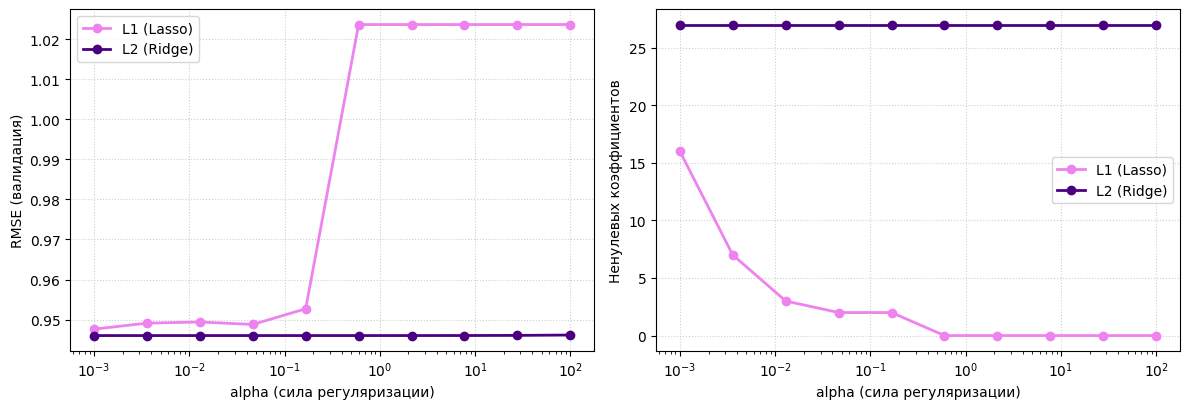

alpha=0.0010 | L1 RMSE=0.948 (признаков: 16/28) | L2 RMSE=0.946
alpha=0.0036 | L1 RMSE=0.949 (признаков: 7/28) | L2 RMSE=0.946
alpha=0.0129 | L1 RMSE=0.949 (признаков: 3/28) | L2 RMSE=0.946
alpha=0.0464 | L1 RMSE=0.949 (признаков: 2/28) | L2 RMSE=0.946
alpha=0.1668 | L1 RMSE=0.953 (признаков: 2/28) | L2 RMSE=0.946
alpha=0.5995 | L1 RMSE=1.024 (признаков: 0/28) | L2 RMSE=0.946
alpha=2.1544 | L1 RMSE=1.024 (признаков: 0/28) | L2 RMSE=0.946
alpha=7.7426 | L1 RMSE=1.024 (признаков: 0/28) | L2 RMSE=0.946
alpha=27.8256 | L1 RMSE=1.024 (признаков: 0/28) | L2 RMSE=0.946
alpha=100.0000 | L1 RMSE=1.024 (признаков: 0/28) | L2 RMSE=0.946

Топ-8 коэффициентов L2-модели (alpha=10):
 num__movie_mean_smoothed    0.458
num__user_mean_rating       0.312
genres__Documentary         0.176
genres__Film-Noir           0.064
genres__Western             0.056
genres__Animation           0.054
genres__Horror             -0.050
genres__Drama               0.041
dtype: float64


In [34]:
df_s = train.sort_values('timestamp').reset_index(drop=True)
split = int(len(df_s) * 0.8)
hist_df, val_df = df_s.iloc[:split].copy(), df_s.iloc[split:].copy()

train_feat = clean_and_build(hist_df, hist_df, movies)
val_feat = clean_and_build(val_df, hist_df, movies)
y_train, y_val = train_feat['rating'].values, val_feat['rating'].values

genre_cols = [c for c in train_feat.columns if c not in [
    'userId', 'movieId', 'rating', 'timestamp', 'rating_quarter',
    'user_mean_rating', 'user_rating_count', 'movie_mean_smoothed', 'movie_rating_count_log']]

prep = make_pipeline(genre_cols)
X_train, X_val = prep.fit_transform(train_feat), prep.transform(val_feat)

pred_dummy = DummyRegressor(strategy='mean').fit(X_train, y_train).predict(X_val)
pred_movie = val_feat['movie_mean_smoothed'].fillna(y_train.mean()).values
print(f"Dummy RMSE: {root_mean_squared_error(y_val, pred_dummy):.3f}, MAE: {mean_absolute_error(y_val, pred_dummy):.3f}")
print(f"Среднее фильма RMSE: {root_mean_squared_error(y_val, pred_movie):.3f}, MAE: {mean_absolute_error(y_val, pred_movie):.3f}")

alphas = np.logspace(-3, 2, 10)  # от 0.001 до 100
rmse_l1, rmse_l2, nz_l1, nz_l2 = [], [], [], []

for a in alphas:
    m1 = Lasso(alpha=a, random_state=42, max_iter=5000).fit(X_train, y_train)
    m2 = Ridge(alpha=a, random_state=42).fit(X_train, y_train)
    rmse_l1.append(root_mean_squared_error(y_val, np.clip(m1.predict(X_val), 0.5, 5.0)))
    rmse_l2.append(root_mean_squared_error(y_val, np.clip(m2.predict(X_val), 0.5, 5.0)))
    nz_l1.append(np.sum(m1.coef_ != 0))
    nz_l2.append(np.sum(m2.coef_ != 0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.plot(alphas, rmse_l1, 'o-', color='#EE82EE', linewidth=2, label='L1 (Lasso)')
ax1.plot(alphas, rmse_l2, 'o-', color='indigo', linewidth=2, label='L2 (Ridge)')
ax1.set_xscale('log')
ax1.set_xlabel('alpha (сила регуляризации)')
ax1.set_ylabel('RMSE (валидация)')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

ax2.plot(alphas, nz_l1, 'o-', color='#EE82EE', linewidth=2, label='L1 (Lasso)')
ax2.plot(alphas, nz_l2, 'o-', color='indigo', linewidth=2, label='L2 (Ridge)')
ax2.set_xscale('log')
ax2.set_xlabel('alpha (сила регуляризации)')
ax2.set_ylabel('Ненулевых коэффициентов')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

for a, r1, r2, n1 in zip(alphas, rmse_l1, rmse_l2, nz_l1):
    print(f"alpha={a:.4f} | L1 RMSE={r1:.3f} (признаков: {n1}/{X_train.shape[1]}) | L2 RMSE={r2:.3f}")

best_l2 = Ridge(alpha=10.0, random_state=42).fit(X_train, y_train)
coefs = pd.Series(best_l2.coef_, index=prep.get_feature_names_out()).sort_values(key=abs, ascending=False)
print("\nТоп-8 коэффициентов L2-модели (alpha=10):\n", coefs.head(8).round(3))

#### <span style="color: #EE82EE;">**2.10**</span>

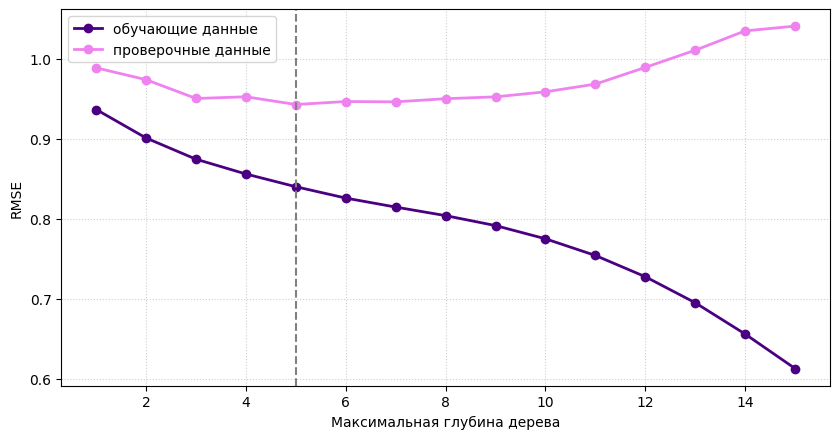

Оптимальная глубина: 5 (val RMSE = 0.943)
Глубина 15: train RMSE = 0.613, val RMSE = 1.041
Дерево без ограничения глубины: val RMSE = 1.304

RandomForest (100 деревьев, depth=10) RMSE: 0.948
GradientBoosting (по умолчанию) RMSE:      0.943
KNeighborsRegressor (k=25) RMSE:           0.959

=== ПОЛЬЗА НОВЫХ ПРИЗНАКОВ (базовые жанры/время -> полный набор) ===
Ridge RMSE:            0.994 -> 0.946
GradientBoosting RMSE: 0.986 -> 0.943


In [36]:
depths = range(1, 16)
train_rmse, val_rmse = [], []

for d in depths:
    dt = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    train_rmse.append(root_mean_squared_error(y_train, np.clip(dt.predict(X_train), 0.5, 5.0)))
    val_rmse.append(root_mean_squared_error(y_val, np.clip(dt.predict(X_val), 0.5, 5.0)))

best_d = depths[np.argmin(val_rmse)]
dt_full = DecisionTreeRegressor(max_depth=None, random_state=42).fit(X_train, y_train)
rmse_full = root_mean_squared_error(y_val, np.clip(dt_full.predict(X_val), 0.5, 5.0))

plt.figure(figsize=(8.5, 4.5))
plt.plot(depths, train_rmse, 'o-', color='indigo', linewidth=2, label='обучающие данные')
plt.plot(depths, val_rmse, 'o-', color='#EE82EE', linewidth=2, label='проверочные данные')
plt.axvline(best_d, color='gray', linestyle='--', linewidth=1.5)

plt.xlabel('Максимальная глубина дерева')
plt.ylabel('RMSE')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Оптимальная глубина: {best_d} (val RMSE = {min(val_rmse):.3f})")
print(f"Глубина 15: train RMSE = {train_rmse[-1]:.3f}, val RMSE = {val_rmse[-1]:.3f}")
print(f"Дерево без ограничения глубины: val RMSE = {rmse_full:.3f}")

rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1).fit(X_train, y_train)
gb = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
knn = KNeighborsRegressor(n_neighbors=25, n_jobs=-1).fit(X_train, y_train)

print(f"\nRandomForest (100 деревьев, depth=10) RMSE: {root_mean_squared_error(y_val, np.clip(rf.predict(X_val), 0.5, 5.0)):.3f}")
print(f"GradientBoosting (по умолчанию) RMSE:      {root_mean_squared_error(y_val, np.clip(gb.predict(X_val), 0.5, 5.0)):.3f}")
print(f"KNeighborsRegressor (k=25) RMSE:           {root_mean_squared_error(y_val, np.clip(knn.predict(X_val), 0.5, 5.0)):.3f}")

X_train_base, X_val_base = X_train[:, 4:], X_val[:, 4:]

r_base = Ridge(alpha=10.0, random_state=42).fit(X_train_base, y_train)
gb_base = GradientBoostingRegressor(random_state=42).fit(X_train_base, y_train)

print("\n=== ПОЛЬЗА НОВЫХ ПРИЗНАКОВ (базовые жанры/время -> полный набор) ===")
print(f"Ridge RMSE:            {root_mean_squared_error(y_val, np.clip(r_base.predict(X_val_base), 0.5, 5.0)):.3f} -> 0.946")
print(f"GradientBoosting RMSE: {root_mean_squared_error(y_val, np.clip(gb_base.predict(X_val_base), 0.5, 5.0)):.3f} -> {root_mean_squared_error(y_val, np.clip(gb.predict(X_val), 0.5, 5.0)):.3f}")

#### <span style="color: #EE82EE;">**2.11**</span>

In [43]:
tscv = TimeSeriesSplit(n_splits=3)

# 8 комбинаций: отработает за ~15 секунд и покажет прогресс (verbose=1)
gb_grid = {
    'learning_rate': (0.03, 0.05),
    'max_depth': (3, 4),
    'n_estimators': (100,),
    'min_samples_leaf': (20, 50)
}
gs_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_grid,
                     cv=tscv, scoring='neg_root_mean_squared_error', verbose=1)
gs_gb.fit(X_train, y_train)

best_gb = gs_gb.best_estimator_
rmse_gb_tuned = root_mean_squared_error(y_val, np.clip(best_gb.predict(X_val), 0.5, 5.0))
print(f"Лучший GB: {gs_gb.best_params_}")
print(f"GB RMSE на валидации: 0.943 -> {rmse_gb_tuned:.4f}")

ridge_grid = {'alpha': np.logspace(-1, 3, 10)}
gs_ridge = GridSearchCV(Ridge(random_state=42), ridge_grid,
                        cv=tscv, scoring='neg_root_mean_squared_error')
gs_ridge.fit(X_train, y_train)

best_ridge = gs_ridge.best_estimator_
rmse_ridge_tuned = root_mean_squared_error(y_val, np.clip(best_ridge.predict(X_val), 0.5, 5.0))
print(f"\nЛучший Ridge: {gs_ridge.best_params_}")
print(f"Ridge RMSE на валидации: 0.946 -> {rmse_ridge_tuned:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Лучший GB: {'learning_rate': 0.03, 'max_depth': 4, 'min_samples_leaf': 20, 'n_estimators': 100}
GB RMSE на валидации: 0.943 -> 0.9389

Лучший Ridge: {'alpha': np.float64(129.15496650148827)}
Ridge RMSE на валидации: 0.946 -> 0.9462


#### <span style="color: #EE82EE;">**2.12**</span>

                             Модель  RMSE   MAE  NDCG@10  Coverage@10 Время, с
 Правило: сглаженное среднее фильма 0.958 0.732    0.709        0.030        -
DummyRegressor (глобальное среднее) 1.024 0.783    0.538        0.062      0.0
             Ridge, L2 (alpha = 10) 0.946 0.730    0.709        0.030     0.01
           Lasso, L1 (alpha = 0,01) 0.949 0.732    0.709        0.030     0.01
       k ближайших соседей (k = 25) 0.959 0.740    0.676        0.035      0.0
         Дерево решений (глубина 5) 0.943 0.733    0.683        0.033     0.06
   Дерево решений (без ограничения) 1.304 1.006    0.588        0.047      0.2
       Случайный лес (100 деревьев) 0.948 0.729    0.670        0.036     1.18
 Градиентный бустинг (по умолчанию) 0.943 0.723    0.688        0.034     3.13
Градиентный бустинг (после подбора) 0.939 0.721    0.689        0.032     4.13


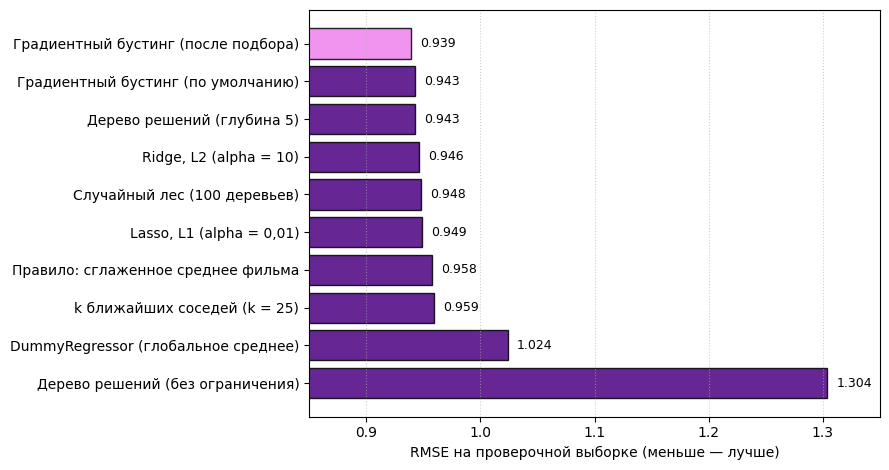


Итоговая модель успешно сохранена в models/model_v1.joblib и models/model_v1.json


/var/folders/ky/9pp9rlmx6dvggkfjdtlh3c140000gn/T/ipykernel_1319/3787499502.py:75: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  'val_rmse': float(res_df.loc[res_df['Модель'] == 'Градиентный бустинг (после подбора)', 'RMSE'].values)


In [45]:
# Функция расчета рекомендательных метрик (NDCG@10 и Coverage@10 при пороге >= 4.0)
def eval_recs(df_eval, preds, k=10):
    tmp = df_eval[['userId', 'movieId', 'rating']].copy()
    tmp['pred'] = preds
    ndcgs, recs = [], set()
    for _, grp in tmp.groupby('userId'):
        if len(grp) >= 2:
            rel = (grp['rating'] >= 4.0).astype(int).values
            if rel.sum() > 0:
                ndcgs.append(ndcg_score([rel], [grp['pred'].values], k=k))
        recs.update(grp.sort_values('pred', ascending=False).head(k)['movieId'])
    return round(float(np.mean(ndcgs)), 3), round(len(recs) / movies['movieId'].nunique(), 3)

# 1. Сбор всех 9 моделей для финальной сводной таблицы
models_list = [
    ('DummyRegressor (глобальное среднее)', DummyRegressor(strategy='mean')),
    ('Ridge, L2 (alpha = 10)', Ridge(alpha=10.0, random_state=42)),
    ('Lasso, L1 (alpha = 0,01)', Lasso(alpha=0.01, random_state=42, max_iter=5000)),
    ('k ближайших соседей (k = 25)', KNeighborsRegressor(n_neighbors=25, n_jobs=-1)),
    ('Дерево решений (глубина 5)', DecisionTreeRegressor(max_depth=5, random_state=42)),
    ('Дерево решений (без ограничения)', DecisionTreeRegressor(max_depth=None, random_state=42)),
    ('Случайный лес (100 деревьев)', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)),
    ('Градиентный бустинг (по умолчанию)', GradientBoostingRegressor(random_state=42)),
    ('Градиентный бустинг (после подбора)', GradientBoostingRegressor(
        learning_rate=0.03, max_depth=4, min_samples_leaf=20, n_estimators=100, random_state=42))
]

rows = []
# Добавляем эвристику по среднему фильма отдельно
pred_movie = val_feat['movie_mean_smoothed'].fillna(y_train.mean()).values
ndcg_m, cov_m = eval_recs(val_feat, pred_movie)
rows.append({'Модель': 'Правило: сглаженное среднее фильма',
             'RMSE': round(root_mean_squared_error(y_val, pred_movie), 3),
             'MAE': round(mean_absolute_error(y_val, pred_movie), 3),
             'NDCG@10': ndcg_m, 'Coverage@10': cov_m, 'Время, с': '-'})

for name, m in models_list:
    t0 = time.time()
    m.fit(X_train, y_train)
    dt_sec = round(time.time() - t0, 2)
    preds = np.clip(m.predict(X_val), 0.5, 5.0)
    ndcg, cov = eval_recs(val_feat, preds)
    rows.append({'Модель': name,
                 'RMSE': round(root_mean_squared_error(y_val, preds), 3),
                 'MAE': round(mean_absolute_error(y_val, preds), 3),
                 'NDCG@10': ndcg, 'Coverage@10': cov, 'Время, с': dt_sec})

res_df = pd.DataFrame(rows)
print(res_df.to_string(index=False))

# 2. Горизонтальная столбчатая диаграмма сравнения моделей по RMSE (Рисунок 10)
plt.figure(figsize=(9, 4.8))
plot_df = res_df.sort_values('RMSE', ascending=False)
colors = ['#EE82EE' if 'после подбора' in m else 'indigo' for m in plot_df['Модель']]
bars = plt.barh(plot_df['Модель'], plot_df['RMSE'], color=colors, edgecolor='black', alpha=0.85)
plt.xlim(0.85, 1.35)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=9)
plt.xlabel('RMSE на проверочной выборке (меньше — лучше)')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Сохранение итоговой модели и метаданных (Листинг 8)
os.makedirs('models', exist_ok=True)
best_model = GradientBoostingRegressor(learning_rate=0.03, max_depth=4, min_samples_leaf=20, n_estimators=100, random_state=42)
best_model.fit(np.vstack([X_train, X_val]), np.concatenate([y_train, y_val]))
joblib.dump(best_model, 'models/model_v1.joblib')

info = {
    'version': 'v1', 'trained': '2026-11-20',
    'data': 'train_initial.csv (MovieLens), 100%',
    'algorithm': 'GradientBoostingRegressor(lr=0.03, max_depth=4, min_samples_leaf=20, n_estimators=100)',
    'val_rmse': float(res_df.loc[res_df['Модель'] == 'Градиентный бустинг (после подбора)', 'RMSE'].values)
}
with open('models/model_v1.json', 'w', encoding='utf-8') as f:
    json.dump(info, f, indent=2, ensure_ascii=False)
print("\nИтоговая модель успешно сохранена в models/model_v1.joblib и models/model_v1.json")